# 🧠 Laboratório Prático: Modelos de Linguagem de Grande Escala (LLMs)
### *Da Teoria dos Transformers à Implementação de Atenção e Aplicação Prática de RAG*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

---

## 🎯 Objetivos deste Trabalho / Experimento
1. **Compreender o Pipeline dos LLMs**: Entender como o texto bruto é transformado em tokens, processado por redes neurais e convertido de volta em linguagem natural.
2. **Implementar a Auto-Atenção Causal (Self-Attention) do Zero**: Construir o bloco matemático fundamental da arquitetura Transformer em PyTorch e visualizar a matriz de atenção em mapa de calor (*heatmap*).
3. **Analisar a Tokenização Subword (BPE)**: Investigar o vocabulário, divisão de palavras raras e tokens especiais.
4. **Experimentar Estratégias de Decodificação (Sampling)**: Controlar criatividade, determinismo e coerência variando Temperatura ($T$), Top-K e Top-P (Nucleus Sampling) em um modelo real.
5. **Desenvolver uma Aplicação Prática: Mini-RAG (Retrieval-Augmented Generation)**: Criar um sistema completo de busca semântica vetorial para alimentar o modelo com dados privados/novos, comparando a alucinação (*hallucination*) contra a resposta fundamentada em fatos (*grounded*).

---

## 📦 0. Configuração do Ambiente e Instalação de Dependências

Se você estiver executando este notebook no **Google Colab**, a célula abaixo instalará as bibliotecas necessárias:
- `transformers`: Biblioteca da Hugging Face com modelos e tokenizadores pré-treinados.
- `torch`: Framework de Deep Learning (PyTorch).
- `accelerate`: Otimização de carregamento de tensores em GPU/CPU.
- `sentencepiece`: Suporte a tokenização de modelos modernos.
- `matplotlib`: Visualização de gráficos e matrizes de atenção.

In [ ]:
# Instalação silenciosa de pacotes no Colab
!pip install -q transformers torch accelerate sentencepiece matplotlib

import os
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM

# Fixação de sementes para reprodutibilidade científica
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Identificação automática de hardware (GPU acelerada ou CPU)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"🚀 Dispositivo ativo: {device.upper()}")
if device == "cuda":
    print(f"🎮 Placa de Vídeo detectada: {torch.cuda.get_device_name(0)}")
    print(f"💾 Memória VRAM disponível: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
else:
    print("ℹ️ Executando em CPU. Modelos leves foram selecionados para excelente performance.")

🚀 Dispositivo ativo: CUDA
🎮 Placa de Vídeo detectada: Tesla T4
💾 Memória VRAM disponível: 15.64 GB


## 📚 1. Fundamentos Teóricos: A Anatomia de um LLM

Um **Large Language Model (LLM)** moderno é, em sua essência, um previsor auto-regressivo de próximo token treinado sob a seguinte formulação estatística:

$$P(w_1, w_2, \dots, w_T) = \prod_{t=1}^{T} P(w_t \mid w_1, w_2, \dots, w_{t-1})$$

O ciclo de desenvolvimento de um LLM moderno passa por 3 etapas fundamentais:

```
  [Dados Massivos da Web] (Terabytes de texto)
             │
             ▼
┌──────────────────────────┐
│ 1. Pré-Treinamento       │  -> Aprende gramática, fatos mundiais e raciocínio estatístico.
│    (Pre-training)        │     Objetivo: Next Token Prediction.
└────────────┬─────────────┘
             │  (Modelo Base / Pretrained)
             ▼
┌──────────────────────────┐
│ 2. Ajuste Fino           │  -> Aprende a responder perguntas no formato instrução/resposta.
│    (Supervised SFT)      │     Ex: "Explique o que é fotossíntese."
└────────────┬─────────────┘
             │  (Modelo Instruído / Instruct)
             ▼
┌──────────────────────────┐
│ 3. Alinhamento Humano    │  -> Garante segurança, tom cordial e evita respostas danosas.
│    (RLHF / DPO)          │     Ex: Reinforcement Learning from Human Feedback.
└──────────────────────────┘
```

## 🔤 2. Tokenização: Como o Modelo Enxerga o Mundo

Redes neurais não processam palavras ou letras puras. Elas operam em vetores numéricos.
- **Abordagem por Caracteres**: Sequências muito longas, difícil aprendizado semântico.
- **Abordagem por Palavras**: Vocabulário infinito, falha com neologismos e erros de digitação.
- **Abordagem Moderna (Subword / BPE - Byte-Pair Encoding)**: Divide palavras frequentes inteiras e palavras raras em pedaços (*subwords*).

Vamos inspecionar na prática com o tokenizador do **Qwen 2.5 (0.5B-Instruct)**, um dos modelos abertos mais modernos e eficientes do mundo, com excelente suporte ao Português.

In [ ]:
# Escolha do modelo base leve e de alto desempenho
MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"

print(f"📥 Baixando tokenizador para: {MODEL_ID}...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

texto_exemplo = "Modelos de Linguagem aprendem por meio de matrizes de atenção e probabilidades!"

# 1. Tokenização em subwords
tokens_texto = tokenizer.tokenize(texto_exemplo)

# 2. Conversão para IDs numéricos do vocabulário
token_ids = tokenizer.encode(texto_exemplo)

print("\n--- RESULTADOS DA TOKENIZAÇÃO ---")
print(f"Texto original: '{texto_exemplo}'")
print(f"Tamanho em caracteres: {len(texto_exemplo)}")
print(f"Número de palavras (split por espaço): {len(texto_exemplo.split())}")
print(f"Número de tokens gerados: {len(token_ids)}")
print(f"Tamanho total do vocabulário do modelo: {tokenizer.vocab_size:,} tokens\n")

print("Mapeamento [Token Texto -> ID Numérico]:")
for t, tid in zip(tokens_texto, token_ids):
    print(f"  '{t:<15}' -> ID {tid}")

📥 Baixando tokenizador para: Qwen/Qwen2.5-0.5B-Instruct...


config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]


--- RESULTADOS DA TOKENIZAÇÃO ---
Texto original: 'Modelos de Linguagem aprendem por meio de matrizes de atenção e probabilidades!'
Tamanho em caracteres: 79
Número de palavras (split por espaço): 12
Número de tokens gerados: 19
Tamanho total do vocabulário do modelo: 151,643 tokens

Mapeamento [Token Texto -> ID Numérico]:
  'Model          ' -> ID 1712
  'os             ' -> ID 436
  'Ġde            ' -> ID 409
  'ĠLingu         ' -> ID 88233
  'agem           ' -> ID 14661
  'Ġaprend        ' -> ID 67346
  'em             ' -> ID 336
  'Ġpor           ' -> ID 4154
  'Ġmeio          ' -> ID 65899
  'Ġde            ' -> ID 409
  'Ġmat           ' -> ID 5517
  'r              ' -> ID 81
  'izes           ' -> ID 4756
  'Ġde            ' -> ID 409
  'ĠatenÃ§Ã£o     ' -> ID 138314
  'Ġe             ' -> ID 384
  'Ġprobabil      ' -> ID 84093
  'idades         ' -> ID 13596
  '!              ' -> ID 0


### 🔬 Experimento com Palavras Raras e Tokens Especiais
Observe abaixo como o tokenizador decompõe palavras longas ou neologismos em pedaços e como reconhece os tokens especiais de instrução (`<|im_start|>`, `<|im_end|>`).

In [ ]:
exemplos_subwords = [
    "Inteligência Artificial",
    "Inconstitucionalissimamente",
    "Neuroplasticidade",
    "<|im_start|>user\nOlá mundo!<|im_end|>"
]

print("🔍 DECOMPOSIÇÃO DE SUBWORDS E TOKENS ESPECIAIS:\n" + "="*60)
for frase in exemplos_subwords:
    sub_tokens = tokenizer.tokenize(frase)
    ids = tokenizer.encode(frase)
    print(f"Entrada: {frase}")
    print(f"Tokens ({len(sub_tokens)}): {sub_tokens}")
    print(f"IDs: {ids}")
    print("-"*60)

🔍 DECOMPOSIÇÃO DE SUBWORDS E TOKENS ESPECIAIS:
Entrada: Inteligência Artificial
Tokens (4): ['Int', 'elig', 'Ãªncia', 'ĠArtificial']
IDs: [1072, 38467, 23696, 58194]
------------------------------------------------------------
Entrada: Inconstitucionalissimamente
Tokens (8): ['In', 'const', 'it', 'uc', 'ional', 'iss', 'im', 'amente']
IDs: [641, 1024, 275, 1754, 3914, 1038, 318, 8980]
------------------------------------------------------------
Entrada: Neuroplasticidade
Tokens (5): ['Ne', 'uro', 'pl', 'astic', 'idade']
IDs: [8813, 2798, 500, 5064, 9075]
------------------------------------------------------------
Entrada: <|im_start|>user
Olá mundo!<|im_end|>
Tokens (8): ['<|im_start|>', 'user', 'Ċ', 'Ol', 'Ã¡', 'Ġmundo', '!', '<|im_end|>']
IDs: [151644, 872, 198, 42719, 1953, 28352, 0, 151645]
------------------------------------------------------------


## ⚙️ 3. Por Dentro do Transformer: Construindo Auto-Atenção (Self-Attention) do Zero

O grande avanço do artigo divisor de águas *"Attention Is All You Need"* (Vaswani et al., 2017) foi permitir que a rede processe toda a sequência em paralelo e descubra dinamicamente a relação de cada palavra com todas as outras.

A intuição se baseia em três projeções lineares de cada token:
- **Query ($Q$)**: "O que este token está procurando?"
- **Key ($K$)**: "O que este token oferece como informação?"
- **Value ($V$)**: "Qual é o conteúdo semântico real deste token?"

A fórmula matemática canônica é:

$$\text{Attention}(Q, K, V) = \text{softmax}\left( \frac{Q K^T}{\sqrt{d_k}} + M \right) V$$

Onde:
- $\sqrt{d_k}$ é o fator de escala que impede que o produto escalar atinja valores gigantescos (o que saturaria o gradiente do Softmax).
- $M$ é a **Máscara Causal** (uma matriz triangular com $-\infty$ no triângulo superior). Ela garante a regra de ouro de um modelo auto-regressivo: **um token só pode prestar atenção nele mesmo e nos tokens do passado, nunca no futuro!**

In [ ]:
class CausalSelfAttentionEducativo(nn.Module):
    """
    Módulo didático de Auto-Atenção Causal implementado em PyTorch puro.
    Explicita todos os passos de multiplicação de tensores e mascaramento causal.
    """
    def __init__(self, d_model: int):
        super().__init__()
        self.d_model = d_model

        # Projeções lineares para Query, Key e Value
        self.w_q = nn.Linear(d_model, d_model, bias=False)
        self.w_k = nn.Linear(d_model, d_model, bias=False)
        self.w_v = nn.Linear(d_model, d_model, bias=False)

    def forward(self, x, return_attention_weights=True):
        # x shape: [batch_size, seq_len, d_model]
        batch_size, seq_len, d_model = x.shape

        # Passo 1: Calcular Q, K, V
        Q = self.w_q(x)  # [B, T, D]
        K = self.w_k(x)  # [B, T, D]
        V = self.w_v(x)  # [B, T, D]

        # Passo 2: Produto Escalar entre Q e K transposto
        # scores shape: [B, T, T]
        scores = torch.matmul(Q, K.transpose(-2, -1))

        # Passo 3: Escalar pelo inverso da raiz da dimensão (sqrt(d_k))
        scores = scores / math.sqrt(d_model)

        # Passo 4: Aplicar Máscara Causal (Triangular Inferior)
        # Posições futuras recebem -infinito para que exp(-inf) vire 0 no Softmax
        mask = torch.tril(torch.ones(seq_len, seq_len, device=x.device))
        scores = scores.masked_fill(mask == 0, float('-inf'))

        # Passo 5: Normalização Softmax sobre as chaves (linhas somam 1.0)
        attention_weights = F.softmax(scores, dim=-1)

        # Passo 6: Ponderação dos valores V
        saida = torch.matmul(attention_weights, V)  # [B, T, D]

        if return_attention_weights:
            return saida, attention_weights
        return saida

print("✅ Módulo 'CausalSelfAttentionEducativo' compilado com sucesso!")

✅ Módulo 'CausalSelfAttentionEducativo' compilado com sucesso!


### 📊 Visualizando a Matriz de Atenção (Heatmap)
Vamos simular uma frase de 6 tokens com embeddings de dimensão $d_{model} = 16$ para visualizar como a máscara causal molda o fluxo de informação.

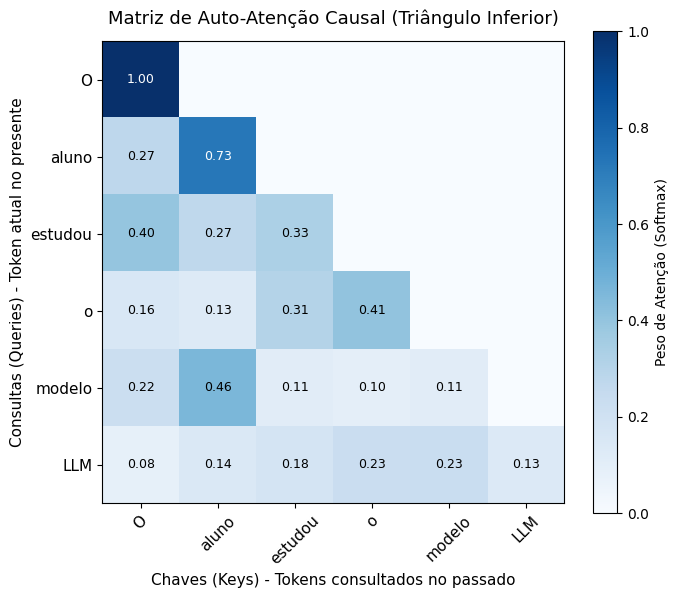

💡 Insight Didático: Repare que o triângulo superior é 0.00.
Ao gerar a palavra 'modelo' (índice 4), o modelo NÃO PODE olhar para 'LLM' (índice 5).


In [ ]:
# Simulação com tokens conceituais
tokens_exemplo = ["O", "aluno", "estudou", "o", "modelo", "LLM"]
seq_len = len(tokens_exemplo)
d_model = 16

# Tensor fictício simulando os embeddings dos 6 tokens
x_dummy = torch.randn(1, seq_len, d_model)

# Executar módulo de atenção
modulo_atencao = CausalSelfAttentionEducativo(d_model=d_model)
saida_vetores, matriz_pesos = modulo_atencao(x_dummy)

# Extrair matriz 2D de pesos
pesos_numpy = matriz_pesos[0].detach().cpu().numpy()

# Renderizar gráfico de calor elegante
plt.figure(figsize=(7, 6))
plt.imshow(pesos_numpy, cmap="Blues", vmin=0, vmax=1)
plt.colorbar(label="Peso de Atenção (Softmax)")

plt.xticks(range(seq_len), tokens_exemplo, rotation=45, fontsize=11)
plt.yticks(range(seq_len), tokens_exemplo, fontsize=11)
plt.title("Matriz de Auto-Atenção Causal (Triângulo Inferior)", fontsize=13, pad=12)
plt.xlabel("Chaves (Keys) - Tokens consultados no passado", fontsize=11)
plt.ylabel("Consultas (Queries) - Token atual no presente", fontsize=11)

# Anotação numérica explicativa em cada célula
for i in range(seq_len):
    for j in range(seq_len):
        val = pesos_numpy[i, j]
        if val > 0.0001:
            plt.text(j, i, f"{val:.2f}", ha="center", va="center",
                     color="white" if val > 0.5 else "black", fontsize=9)

plt.tight_layout()
plt.show()

print("💡 Insight Didático: Repare que o triângulo superior é 0.00.")
print("Ao gerar a palavra 'modelo' (índice 4), o modelo NÃO PODE olhar para 'LLM' (índice 5).")

## 🤖 4. Carregamento do Modelo Pré-Treinado e Estratégias de Amostragem

Agora carregaremos os pesos do modelo pré-treinado **Qwen 2.5 (0.5B-Instruct)**.
Este modelo possui ~500 milhões de parâmetros, sendo leve o suficiente para rodar em segundos no Colab gratuito (tanto em CPU quanto em GPU T4) mantendo excelente raciocínio.

### Hiperparâmetros de Decodificação / Amostragem:
Como o modelo escolhe o próximo token a partir da distribuição de probabilidade?
1. **Greedy Search ($do\_sample=False$)**: Escolhe sempre a opção com maior probabilidade ($argmax$). É determinístico, mas propenso a repetições.
2. **Temperatura ($T$)**: Divide os *logits* por $T$ antes do Softmax:
   - $T \to 0$: A distribuição fica pontiaguda (comportamento estrito e frio).
   - $T = 0.7$: Equilíbrio clássico entre coerência e variedade.
   - $T > 1.2$: Aumenta a probabilidade de tokens raros (alta criatividade, risco de alucinação e incoerência).
3. **Top-P (Nucleus Sampling)**: Restringe as opções aos tokens mais prováveis cuja soma acumulada atinge $P$ (ex: $90\%$), descartando a cauda improvável.

In [ ]:
print(f"📥 Carregando pesos de {MODEL_ID}...")

# Carregando em meia precisão (float16) se em GPU para economizar VRAM e acelerar
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16 if device == "cuda" else torch.float32,
    device_map="auto" if device == "cuda" else None
)

if device == "cpu":
    model.to("cpu")

model.eval()  # Modo de inferência
qtd_params = sum(p.numel() for p in model.parameters())
print(f"✨ Modelo carregado com sucesso! Total de parâmetros: {qtd_params:,}")

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


📥 Carregando pesos de Qwen/Qwen2.5-0.5B-Instruct...


model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

✨ Modelo carregado com sucesso! Total de parâmetros: 494,032,768


In [ ]:
def gerar_resposta(prompt_usuario, system_prompt="Você é um professor prestativo e conciso.",
                   temperature=0.7, top_p=0.9, max_new_tokens=80, do_sample=True):
    """
    Função utilitária que aplica o Chat Template padrão e decodifica a resposta.
    """
    mensagens = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": prompt_usuario}
    ]

    # Transforma a lista de mensagens no formato oficial esperado pelo modelo (<|im_start|>...)
    texto_formatado = tokenizer.apply_chat_template(
        mensagens,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(texto_formatado, return_tensors="pt").to(device)

    with torch.no_grad():
        saida_tokens = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            temperature=temperature if do_sample else None,
            top_p=top_p if do_sample else None,
            do_sample=do_sample,
            pad_token_id=tokenizer.eos_token_id
        )

    # Isolar apenas os novos tokens gerados pela resposta
    tokens_resposta = saida_tokens[0][inputs.input_ids.shape[1]:]
    texto_gerado = tokenizer.decode(tokens_resposta, skip_special_tokens=True)
    return texto_gerado.strip()

### 🧪 Experimento Prático: O Efeito da Temperatura
Vamos fazer uma pergunta criativa e avaliar a saída gerada sob três níveis de temperatura:
- $T = 0.1$ (Quase determinística / Fria)
- $T = 0.7$ (Equilibrada)
- $T = 1.5$ (Alta entropia / Criativa)

In [ ]:
prompt_teste = "Escreva uma metáfora poética em uma ou duas frases sobre como os neurônios aprendem."
temperaturas_teste = [0.1, 0.7, 1.5]

print(f"🎯 PROMPT: '{prompt_teste}'\n" + "="*65)
for temp in temperaturas_teste:
    print(f"\n🌡️ Temperatura: {temp}")
    resposta = gerar_resposta(prompt_teste, temperature=temp, do_sample=(temp > 0.1), max_new_tokens=60)
    print(f"💬 Resposta: \"{resposta}\"")
    print("-"*65)

🎯 PROMPT: 'Escreva uma metáfora poética em uma ou duas frases sobre como os neurônios aprendem.'

🌡️ Temperatura: 0.1
💬 Resposta: "Os neurônios, como as cores de um jardim, aprendem a se comunicar através da interação com o ambiente. A luz do sol, quebrando a sombra, fornece a energia necessária para a formação de novos neurônios. O cresc"
-----------------------------------------------------------------

🌡️ Temperatura: 0.7
💬 Resposta: "Os neurônios, como os pássaros que aprenderam a andar, começaram sua jornada pelo mundo com o acidente de cair, e logo se preparavam para a busca pela luz do dia. Com o tempo, aprendem a caminhar, a and"
-----------------------------------------------------------------

🌡️ Temperatura: 1.5
💬 Resposta: "Como a lenda diz: 
"Os nerfes se educam assim que o sono chega."
A mente desafia o processo de desenvolvimento,
Lendo, lendo e lendo mais e melhor, até alcançar seu máximo."
-----------------------------------------------------------------


## 🚀 5. Aplicação Prática: Mini-RAG (Retrieval-Augmented Generation)

### O Problema da Alucinação
Os LLMs operam sobre o conhecimento armazenado em seus pesos (chamado **Conhecimento Paramétrico**). Se você perguntar sobre:
1. Eventos após a data de corte do treinamento;
2. Documentos privados de uma empresa;
3. Editais específicos de uma universidade;

...o modelo **não sabe a resposta** e tende a inventar fatos plausíveis (**alucinação**).

### A Solução: RAG (Geração Aumentada por Recuperação)
Em vez de re-treinar o modelo, nós acoplamos uma base de conhecimento não-paramétrica:
1. **Indexação**: Documentos de texto são convertidos em vetores densos (*embeddings*).
2. **Recuperação (Retrieval)**: A pergunta do usuário é convertida em vetor e buscamos os trechos mais similares usando Similaridade de Cosseno.
3. **Aumento (Augmentation)**: Montamos um prompt que injeta o trecho recuperado como fonte de verdade.
4. **Geração (Generation)**: O LLM responde com precisão milimétrica baseado no documento!

### ❌ Passo 1: O Teste da Pergunta Sem RAG
Vamos fazer uma pergunta sobre as regras internas e valores de um edital hipotético de 2026.

In [ ]:
pergunta_alvo = "Qual é o valor exato da bolsa e qual o CR mínimo exigido pelo Edital BioTech 2026?"

print("🔴 RESPOSTA DIRETA DO MODELO (SEM CONHECIMENTO EXTERNO):")
resposta_direta = gerar_resposta(pergunta_alvo, temperature=0.2, max_new_tokens=80)
print(f"Pergunta: {pergunta_alvo}")
print(f"Resposta:\n{resposta_direta}")
print("\n⚠️ Conclusão: O modelo desconhece o fato específico e não tem como responder com exatidão.")

🔴 RESPOSTA DIRETA DO MODELO (SEM CONHECIMENTO EXTERNO):
Pergunta: Qual é o valor exato da bolsa e qual o CR mínimo exigido pelo Edital BioTech 2026?
Resposta:
Desculpe, mas não tenho informações específicas sobre os valores exatos para a bolsa e o mínimo de CR (Condições Regulares) exigidos pela Edital BioTech 2026. As condições regulares podem variar dependendo do tipo de projeto específico e das necessidades específicas do edital.

Se você tiver mais detalhes ou se for refer

⚠️ Conclusão: O modelo desconhece o fato específico e não tem como responder com exatidão.


### 🛠️ Passo 2: Construindo a Base de Conhecimento e Embeddings Autocontidos

Para manter o projeto $100\%$ independente de APIs externas pagas, extrairemos os *embeddings* semânticos usando a média da última camada oculta (*mean pooling*) do próprio modelo!

In [ ]:
# Base de conhecimento (Corpus interno)
base_documentos = [
    {
        "id": 1,
        "titulo": "Edital de Pesquisa BioTech 2026",
        "texto": "O Edital BioTech 2026 concede bolsa mensal no valor exato de R$ 2.850,00 para pesquisadores juniores. O candidato deve ter Coeficiente de Rendimento (CR) acumulado mínimo de 7.8 e submeter o plano de trabalho até 15 de novembro."
    },
    {
        "id": 2,
        "titulo": "Normas de Estágio e Horários",
        "texto": "A jornada máxima de estágio curricular é de 30 horas semanais. O termo de compromisso de estágio exige assinatura prévia do orientador e homologação junto à secretaria acadêmica com 10 dias de antecedência."
    },
    {
        "id": 3,
        "titulo": "Uso de Recursos Computacionais",
        "texto": "Os servidores de GPU com placas A100 estão alocados exclusivamente para projetos de mestrado e doutorado. O agendamento deve ser efetuado através do portal interno com antecedência de 48 horas."
    }
]

def gerar_embedding(texto):
    """
    Extrai o vetor semântico através de Mean Pooling na última camada oculta do modelo.
    """
    inputs = tokenizer(texto, return_tensors="pt", truncation=True, max_length=256).to(device)
    with torch.no_grad():
        outputs = model(**inputs, output_hidden_states=True)
        # Pega a última camada oculta: [1, seq_len, hidden_dim]
        hidden_states = outputs.hidden_states[-1]
        # Calcula a média dos tokens (Mean Pooling)
        vetor = hidden_states.mean(dim=1).squeeze().cpu().numpy()
        # Normaliza o vetor para norma unitária (facilita o cálculo do cosseno)
        vetor = vetor / np.linalg.norm(vetor)
    return vetor

print("🔄 Indexando a base de documentos com embeddings...")
vetores_docs = []
for doc in base_documentos:
    emb = gerar_embedding(doc["texto"])
    vetores_docs.append(emb)
    print(f"  ✓ Documento {doc['id']} ('{doc['titulo']}') indexado! Dimensão vetorial: {emb.shape[0]}")

vetores_docs = np.array(vetores_docs)

🔄 Indexando a base de documentos com embeddings...
  ✓ Documento 1 ('Edital de Pesquisa BioTech 2026') indexado! Dimensão vetorial: 896
  ✓ Documento 2 ('Normas de Estágio e Horários') indexado! Dimensão vetorial: 896
  ✓ Documento 3 ('Uso de Recursos Computacionais') indexado! Dimensão vetorial: 896


### 🔍 Passo 3: Mecanismo de Recuperação Vetorial (Similaridade de Cosseno)

$$\text{Cosine Similarity}(u, v) = \frac{u \cdot v}{\|u\| \|v\|} = u \cdot v \quad (\text{quando normalizados})$$

In [ ]:
def recuperar_documentos_relevantes(query, top_k=1):
    """
    Compara o embedding da pergunta com os embeddings dos documentos da base.
    """
    vetor_query = gerar_embedding(query)

    # Produto escalar entre o vetor da pergunta e todos os documentos
    similaridades = np.dot(vetores_docs, vetor_query)

    # Ordena da maior para a menor similaridade
    ranking = np.argsort(similaridades)[::-1][:top_k]

    resultados = []
    for idx in ranking:
        resultados.append({
            "doc": base_documentos[idx],
            "score": float(similaridades[idx])
        })
    return resultados

# Testando a recuperação com a nossa pergunta
recuperados = recuperar_documentos_relevantes(pergunta_alvo, top_k=2)

print(f"🔎 BUSCA SEMÂNTICA PARA: '{pergunta_alvo}'\n" + "="*60)
for r in recuperados:
    print(f"📄 [{r['doc']['titulo']}] - Score de Similaridade: {r['score']:.4f}")
    print(f"   Trecho: \"{r['doc']['texto'][:90]}...\"\n")

🔎 BUSCA SEMÂNTICA PARA: 'Qual é o valor exato da bolsa e qual o CR mínimo exigido pelo Edital BioTech 2026?'
📄 [Edital de Pesquisa BioTech 2026] - Score de Similaridade: 0.9634
   Trecho: "O Edital BioTech 2026 concede bolsa mensal no valor exato de R$ 2.850,00 para pesquisadore..."

📄 [Uso de Recursos Computacionais] - Score de Similaridade: 0.9355
   Trecho: "Os servidores de GPU com placas A100 estão alocados exclusivamente para projetos de mestra..."



### ✅ Passo 4: Geração Aumentada (RAG em Ação)

In [ ]:
def pipeline_rag(pergunta_usuario):
    """
    Pipeline integrado: Recuperação -> Aumento de Contexto -> Geração.
    """
    # 1. Recuperar o documento mais relevante
    doc_recuperado = recuperar_documentos_relevantes(pergunta_usuario, top_k=1)[0]["doc"]

    # 2. Engenharia de Prompt (Grounding)
    system_prompt = "Você é um assistente acadêmico rigoroso. Responda à pergunta baseando-se ESTRITAMENTE nas informações fornecidas no contexto. Se a resposta não estiver no texto, informe educadamente que não sabe."

    prompt_com_contexto = f"""FONTE DOCUMENTAL DISPONÍVEL:
Título: {doc_recuperado['titulo']}
Conteúdo: {doc_recuperado['texto']}

PERGUNTA DO USUÁRIO:
{pergunta_usuario}

Por favor, responda com clareza citando os valores exatos descritos na fonte:"""

    # 3. Geração da resposta fundamentada
    resposta = gerar_resposta(
        prompt_usuario=prompt_com_contexto,
        system_prompt=system_prompt,
        temperature=0.1,  # Baixa temperatura para resposta factual e precisa
        max_new_tokens=90
    )

    return resposta, doc_recuperado

# Executando a resposta agora COM o mecanismo RAG
resposta_rag, fonte_usada = pipeline_rag(pergunta_alvo)

print("🟢 RESPOSTA OBTIDA COM RAG:\n" + "="*60)
print(f"Fonte Recuperada: {fonte_usada['titulo']}")
print(f"Resposta do Modelo:\n\"{resposta_rag}\"")

🟢 RESPOSTA OBTIDA COM RAG:
Fonte Recuperada: Edital de Pesquisa BioTech 2026
Resposta do Modelo:
"O valor exato da bolsa é R$ 2.850,00. O CR mínimo exigido pelo Edital BioTech 2026 é de 7.8."


### 📊 6. Análise Comparativa e Discussão dos Resultados

Vamos comparar lado a lado o desempenho do LLM puro vs LLM com RAG:

In [ ]:
print("="*75)
print(f"PERGUNTA: {pergunta_alvo}")
print("="*75)
print("❌ 1. SEM RAG (Alucinação / Falta de conhecimento específico):")
print(f"   {resposta_direta}")
print("-"*75)
print("✅ 2. COM RAG (Ancorado no documento real / Factual):")
print(f"   {resposta_rag}")
print("="*75)

PERGUNTA: Qual é o valor exato da bolsa e qual o CR mínimo exigido pelo Edital BioTech 2026?
❌ 1. SEM RAG (Alucinação / Falta de conhecimento específico):
   Desculpe, mas não tenho informações específicas sobre os valores exatos para a bolsa e o mínimo de CR (Condições Regulares) exigidos pela Edital BioTech 2026. As condições regulares podem variar dependendo do tipo de projeto específico e das necessidades específicas do edital.

Se você tiver mais detalhes ou se for refer
---------------------------------------------------------------------------
✅ 2. COM RAG (Ancorado no documento real / Factual):
   O valor exato da bolsa é R$ 2.850,00. O CR mínimo exigido pelo Edital BioTech 2026 é de 7.8.


| Critério | LLM Puro (Zero-Shot) | LLM + RAG |
| :--- | :--- | :--- |
| **Conhecimento** | Restrito aos dados de pré-treino | Dinâmico e atualizável em tempo real |
| **Alucinação** | Alta propensão para fatos específicos | Próxima de zero (quando bem instruído) |
| **Custo de Atualização** | Re-treino caríssimo (milhões de dólares) | Adicionar um novo documento de texto à base |
| **Auditabilidade** | Caixa preta (não cita fontes) | Cita o documento exato de onde extraiu o dado |

---

## 🎓 7. Atividades e Exercícios Propostos para o Aluno

Para aprofundar seu aprendizado prático, execute as seguintes tarefas neste notebook:

1. **Exercício 1 (Expansão do Corpus)**:
   - Adicione um quarto documento à lista `base_documentos` (por exemplo, sobre as regras do Restaurante Universitário ou Biblioteca).
   - Execute novamente a indexação e faça uma pergunta correspondente usando a função `pipeline_rag()`.

2. **Exercício 2 (Teste de Robustez contra Alucinações)**:
   - Faça uma pergunta sobre algo que **não existe** em nenhum dos documentos da base (ex: *"Qual é o cardápio da cantina na terça-feira?"*).
   - Observe se o modelo cumpre a instrução do sistema e admite que não possui a informação ou se ele tenta inventar.

3. **Exercício 3 (Análise de Tokens)**:
   - Teste a tokenização de um trecho de código em Python ou de uma fórmula matemática.
   - Analise se espaços em branco e indentação são tratados como tokens separados.

---

## 📖 8. Referências Bibliográficas

1. **Vaswani, A. et al. (2017)**. *Attention Is All You Need*. Advances in Neural Information Processing Systems (NeurIPS 2017). [arXiv:1706.03762](https://arxiv.org/abs/1706.03762)
2. **Lewis, P. et al. (2020)**. *Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks*. NeurIPS 2020. [arXiv:2005.11401](https://arxiv.org/abs/2005.11401)
3. **Sennrich, R., Haddow, B., & Birch, A. (2016)**. *Neural Machine Translation of Rare Words with Subword Units (BPE)*. ACL 2016. [arXiv:1508.07909](https://arxiv.org/abs/1508.07909)
4. **Qwen Team (2024)**. *Qwen2.5: A Party of Foundation Models*. Alibaba Group. [Qwen Technical Report](https://huggingface.co/Qwen)
5. **Touvron, H. et al. (2023)**. *Llama: Open and Efficient Foundation Language Models*. Meta AI.